# PV generation prediction – HS Ansbach

Hourly measurements from a building at Hochschule Ansbach: horizontal/vertical irradiance,
outdoor temperature and humidity, PV generation, household consumption, grid import/export.

Two parts:
1. **EDA** – how PV output relates to weather and time
2. **Model** – predict hourly PV generation from weather + time, and check whether there's a PV surplus
   (generation > household consumption)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Loading

The export has 4 junk header rows, German column names, `;` separators, decimal commas,
and a units row under the header – so a bit of cleaning first.

In [2]:
# skip the 4 export rows above the header and the units row (index 5) right below it
raw = pd.read_csv("SesKiPvEletric.csv", sep=";", skiprows=[0, 1, 2, 3, 5], decimal=",",
                  encoding="utf-8-sig")

rename = {
    "Unit": "time",
    "Globalstrahlungsfuehler Horizontal": "irr_horiz",
    "Globalstrahlungsfueler Vertikal": "irr_vert",
    "Elektro Feuchtefuehler": "humidity",
    "Elektro Aussentemperatur": "temp",
    "NSHV (Haushaltstrom); consumption general electricity": "house_kwh",
    "PV\xa0power generated 280": "pv_kwh",
}
# the PV header sometimes has a normal space instead of a non-breaking one
raw.columns = [c.replace("\xa0", " ") for c in raw.columns]
rename = {k.replace("\xa0", " "): v for k, v in rename.items()}

df = raw[list(rename)].rename(columns=rename)
df["time"] = pd.to_datetime(df["time"], format="%d.%m.%Y %H:%M:%S")
df = df.set_index("time").apply(pd.to_numeric, errors="coerce")
df = df.interpolate(limit=3).dropna()

print(df.shape, df.index.min(), "->", df.index.max())
df.describe().T.round(2)

(20305, 6) 2020-01-01 00:00:00 -> 2022-04-26 00:00:00


,count,mean,std,min,25%,50%,75%,max
irr_horiz,20305.0,129.95,187.38,2.64,13.81,40.66,165.67,986.21
irr_vert,20305.0,102.33,160.97,2.55,9.49,34.75,102.20,905.19
humidity,20305.0,70.83,15.47,19.39,59.75,74.76,83.84,93.15
temp,20305.0,9.32,7.87,-12.29,2.85,8.22,15.38,33.13
house_kwh,20305.0,0.79,0.78,0.00,0.00,0.90,1.20,16.20
pv_kwh,20305.0,5.36,8.94,0.00,0.00,0.00,7.48,39.70


## EDA

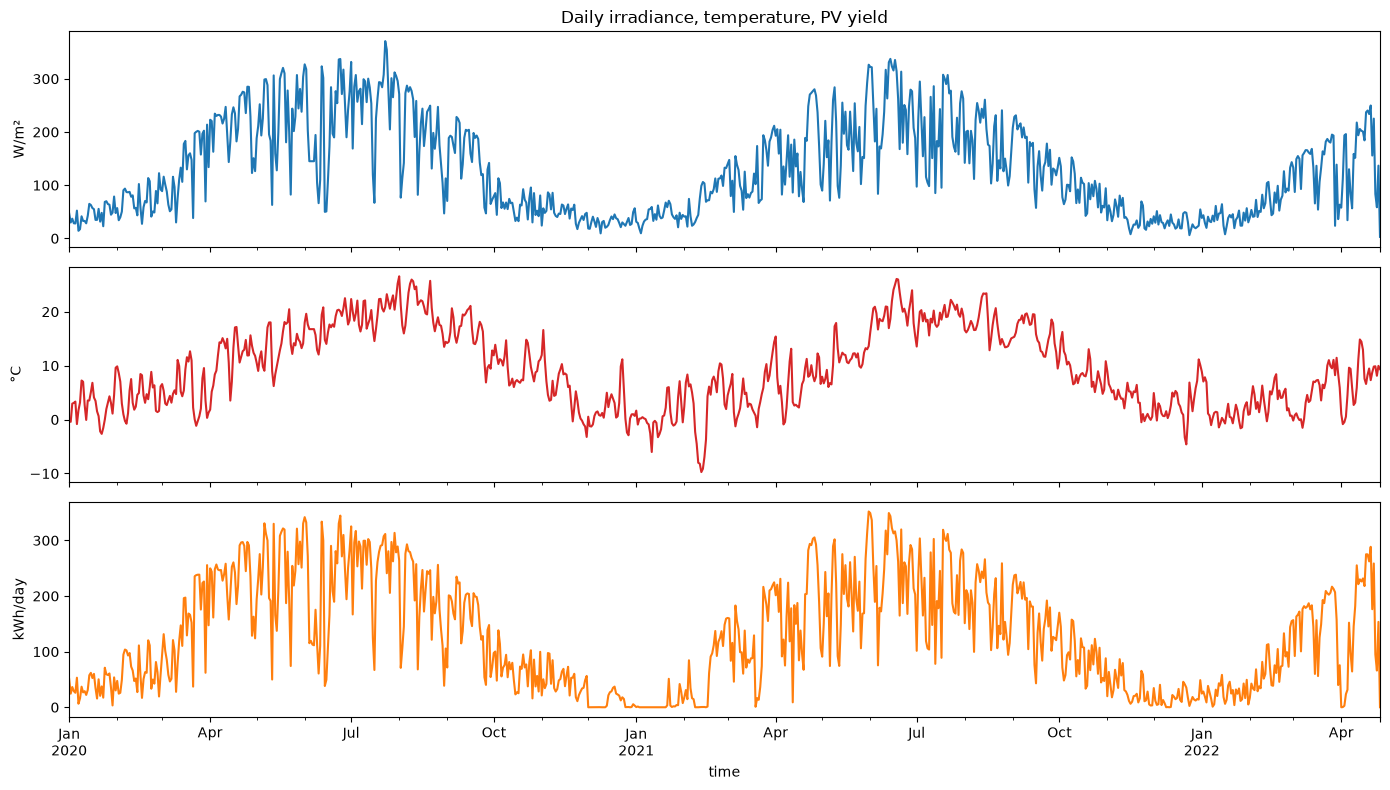

In [3]:
fig, ax = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
df["irr_horiz"].resample("D").mean().plot(ax=ax[0]); ax[0].set_ylabel("W/m²")
df["temp"].resample("D").mean().plot(ax=ax[1], color="tab:red"); ax[1].set_ylabel("°C")
df["pv_kwh"].resample("D").sum().plot(ax=ax[2], color="tab:orange"); ax[2].set_ylabel("kWh/day")
ax[0].set_title("Daily irradiance, temperature, PV yield")
plt.tight_layout(); plt.show()

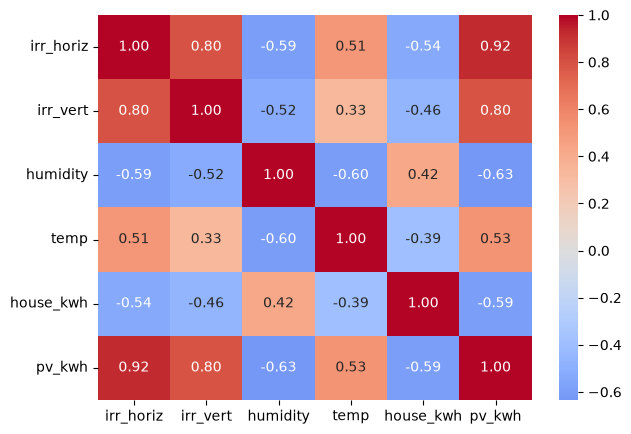

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

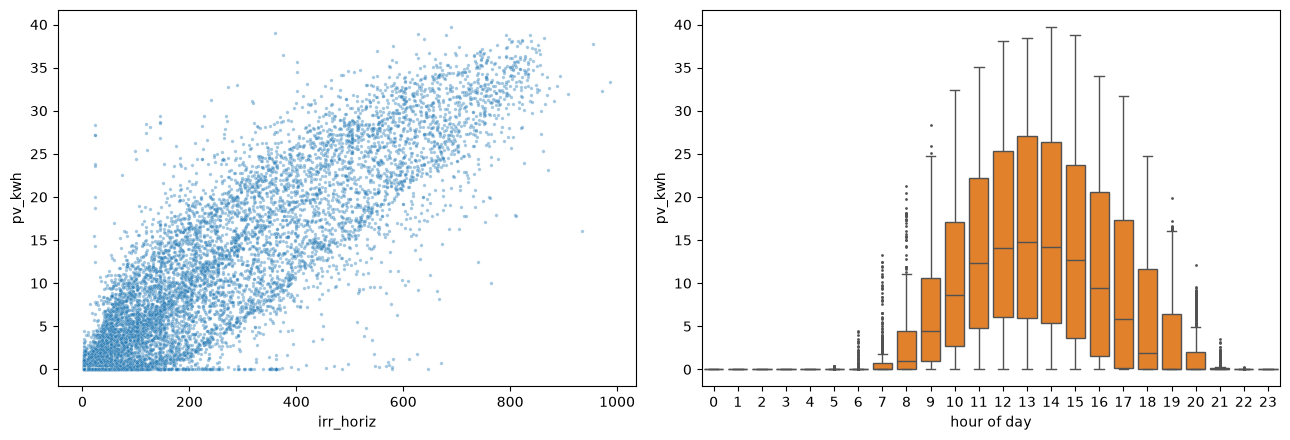

corr(PV, horizontal irradiance) = 0.92
corr(PV, temperature)           = 0.53


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df, x="irr_horiz", y="pv_kwh", s=6, alpha=0.4, ax=ax[0])
sns.boxplot(x=df.index.hour, y=df["pv_kwh"], ax=ax[1], color="tab:orange", fliersize=1)
ax[1].set_xlabel("hour of day")
plt.tight_layout(); plt.show()

print("corr(PV, horizontal irradiance) =", round(df["pv_kwh"].corr(df["irr_horiz"]), 2))
print("corr(PV, temperature)           =", round(df["pv_kwh"].corr(df["temp"]), 2))

Irradiance explains most of PV output (nearly linear). Temperature correlates too, but mostly
because sunny = warm – physically, higher cell temperature actually *reduces* module efficiency.

## Model: PV generation from weather + time

In [6]:
df["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
df["doy_sin"] = np.sin(2 * np.pi * df.index.dayofyear / 365)
df["doy_cos"] = np.cos(2 * np.pi * df.index.dayofyear / 365)

X_cols = ["irr_horiz", "irr_vert", "temp", "humidity", "hour_sin", "hour_cos", "doy_sin", "doy_cos"]

# time-based split: last 20 % of the record is the test set
split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]

models = {
    "Linear (irradiance only)": (LinearRegression(), ["irr_horiz"]),
    "Random forest": (RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1), X_cols),
    "Gradient boosting": (GradientBoostingRegressor(random_state=42), X_cols),
}

rows, preds = [], {}
for name, (mdl, cols) in models.items():
    mdl.fit(train[cols], train["pv_kwh"])
    p = np.clip(mdl.predict(test[cols]), 0, None)  # PV can't be negative
    preds[name] = p
    rows.append({"model": name,
                 "MAE [kWh]": mean_absolute_error(test["pv_kwh"], p),
                 "RMSE [kWh]": np.sqrt(mean_squared_error(test["pv_kwh"], p)),
                 "R²": r2_score(test["pv_kwh"], p)})
pd.DataFrame(rows).set_index("model").round(3)

C:\Users\advai\AppData\Local\Temp\ipykernel_28588\2761112297.py:3: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df["doy_sin"] = np.sin(2 * np.pi * df.index.dayofyear / 365)
C:\Users\advai\AppData\Local\Temp\ipykernel_28588\2761112297.py:4: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df["doy_cos"] = np.cos(2 * np.pi * df.index.dayofyear / 365)


,MAE [kWh],RMSE [kWh],R²
model,,,
Linear (irradiance only),1.540,3.112,0.785
Random forest,1.066,2.654,0.843
Gradient boosting,1.094,2.553,0.855


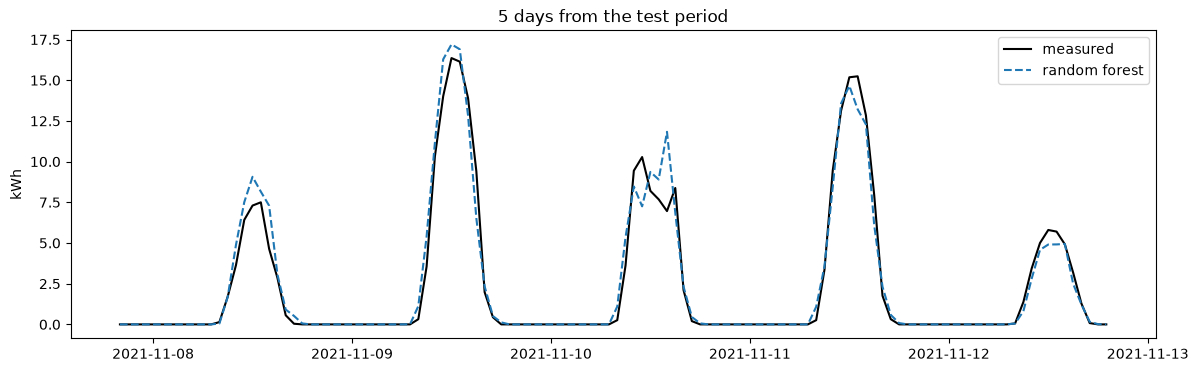

In [7]:
days = slice(0, 24 * 5)
plt.figure(figsize=(14, 4))
plt.plot(test.index[days], test["pv_kwh"].values[days], color="black", label="measured")
plt.plot(test.index[days], preds["Random forest"][days], ls="--", label="random forest")
plt.ylabel("kWh"); plt.legend(); plt.title("5 days from the test period")
plt.show()

## PV surplus

How often does the PV system produce more than the building uses?

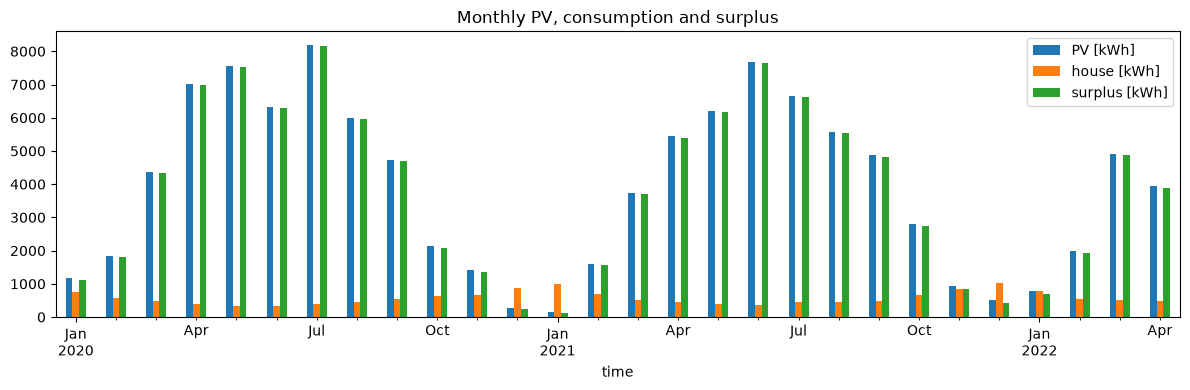

hours with surplus: 41.6%


In [8]:
surplus = (df["pv_kwh"] - df["house_kwh"]).clip(lower=0)
monthly = pd.DataFrame({
    "PV [kWh]": df["pv_kwh"].resample("ME").sum(),
    "house [kWh]": df["house_kwh"].resample("ME").sum(),
    "surplus [kWh]": surplus.resample("ME").sum(),
})
monthly.plot.bar(figsize=(12, 4)); plt.title("Monthly PV, consumption and surplus")
plt.tight_layout(); plt.show()

print(f"hours with surplus: {(surplus > 0).mean():.1%}")